# Certified hybrid decoding: reproducible publication campaign

The authoritative implementation is `selltcfull_experiments.py`; experiment orchestration and all analysis are in `publication_experiments.py`. This notebook contains no duplicate algorithm source.

Run all cells in a Python 3.12 environment installed with `python -m pip install -r requirements-publication.txt`. In a fresh output directory, the declared campaign executes **720 clean trials, 480 corruption trials and 90 separate checker-scaling trials**. When the committed completed run is present, its raw-file checksums are checked and every table and figure is regenerated from those raw files. The stored timing measurements are not claimed to be identical across machines.

Original data in `SELLTCFULL_outputs/` remain unchanged. To measure a new run, invoke `python publication_experiments.py --output publication_outputs_new` in a terminal. The manifest and configuration are written **before** measurement; incomplete directories require a new output name so that interrupted runs remain available.

The sparse replay checker validates a trace and output or impossibility witness. Direct verification checks only a complete word's parity and channel consistency; it cannot certify trace validity or infeasibility. Python is tested, not mechanically verified.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
from publication_experiments import CONFIG, run_campaign
from generate_certificate_cases import generate

OUTPUT_DIR = Path("publication_outputs")
display(pd.Series(CONFIG, name="Declared configuration"))

protocol_version                                                                          1
base_seed                                                                          20260920
families                                                              [random_regular, peg]
dv                                                                                        3
dc                                                                                        6
blocklengths                                                          [128, 256, 512, 1024]
matrix_replicates                                                                         3
epsilons                                                                    [0.3, 0.4, 0.5]
clean_trials_per_matrix_condition                                                        10
robustness_blocklengths                                                          [256, 512]
robustness_epsilons                                                             

## Execute or regenerate the declared run

The three code matrices in each family and size are independent realizations. Channel trials on a matrix are a cluster, not independent matrix samples. The two hybrids and GE-only use the same exact bitset elimination engine. Repetitions are warmed up and measured in a deterministic randomized order. Success means some compatible completion; exact recovery and uniqueness are separate columns.

In [2]:
facts = run_campaign(OUTPUT_DIR)
print(json.dumps(facts, indent=2))

Existing completed run verified; regenerating analysis from raw CSVs.


{
  "clean_trials": 720,
  "robustness_trials": 480,
  "scaling_trials": 90,
  "campaign_matrices": 24,
  "clean_completion_rate": 1.0,
  "clean_exact_recovery_rate": 0.7805555555555556,
  "clean_nonunique_count": 174,
  "clean_nonzero_transmitted_words": "uniform kernel sampling; reproducible using stored seeds",
  "actually_corrupted_robustness": 251,
  "corrupted_compatible": 100,
  "incompatible_robustness": 151,
  "accepted_failure_count": 151,
  "all_generated_certificates_accepted": true,
  "scaling_slopes": [
    {
      "algorithm": "sparse",
      "slope": 1.0457911697986793,
      "lower95": 1.0326995966524144,
      "upper95": 1.0617129894475077,
      "matrices_per_size": 3,
      "sizes": 5
    },
    {
      "algorithm": "direct",
      "slope": 1.0057792360611748,
      "lower95": 1.0028709999489798,
      "upper95": 1.0084598449668531,
      "matrices_per_size": 3,
      "sizes": 5
    },
    {
      "algorithm": "dense",
      "slope": 1.582634533624475,
      "lower9

In [3]:
summary = pd.read_csv(OUTPUT_DIR / "condition_summary.csv")
table = pd.read_csv(OUTPUT_DIR / "table_epsilon040.csv")
assert (table.epsilon == 0.40).all() and (table.delta == 0).all()
display(table)
display(pd.read_csv(OUTPUT_DIR / "scaling_slopes.csv"))

,family,n,epsilon,delta,trials,matrices,completion_rate,acceptance_rate,peeling_completion_rate,exact_recovery_rate,...,total_ms,direct_ms,ge_ms,hybrid_ms,certified_ms,peeling_only_ms,relative_mean_ratio,relative_ratio_means,fraction_mean_ratio,fraction_ratio_means
0,peg,128,0.4,0.0,30,3,1.0,1.0,0.566667,0.966667,...,0.247878,0.091853,0.218793,0.131308,0.249933,0.070253,1.106616,0.921883,0.498549,0.479677
1,peg,256,0.4,0.0,30,3,1.0,1.0,0.666667,1.000000,...,0.524869,0.186288,0.654864,0.285329,0.527507,0.142963,1.147339,0.848900,0.498482,0.459138
2,peg,512,0.4,0.0,30,3,1.0,1.0,0.900000,1.000000,...,0.992636,0.365551,2.228913,0.469728,0.996028,0.307514,1.414548,1.131627,0.567966,0.530875
3,peg,1024,0.4,0.0,30,3,1.0,1.0,0.900000,1.000000,...,2.341864,0.740975,9.168086,1.223744,2.347786,0.657710,1.375881,0.898941,0.555045,0.473391
4,random_regular,128,0.4,0.0,30,3,1.0,1.0,0.400000,0.966667,...,0.258732,0.094028,0.222064,0.140351,0.260776,0.071539,0.989656,0.845633,0.473508,0.458180
5,random_regular,256,0.4,0.0,30,3,1.0,1.0,0.766667,1.000000,...,0.502740,0.184389,0.655932,0.255506,0.505454,0.144071,1.243100,0.968111,0.527154,0.491898
6,random_regular,512,0.4,0.0,30,3,1.0,1.0,0.766667,1.000000,...,1.214382,0.375500,2.317649,0.682157,1.218886,0.310125,1.228649,0.774673,0.512059,0.436516
7,random_regular,1024,0.4,0.0,30,3,1.0,1.0,0.866667,1.000000,...,2.560522,0.739253,9.211350,1.454689,2.566939,0.641255,1.346323,0.755863,0.541151,0.430480


,algorithm,slope,lower95,upper95,matrices_per_size,sizes
0,sparse,1.045791,1.032700,1.061713,3,5
1,direct,1.005779,1.002871,1.008460,3,5
2,dense,1.582635,1.554521,1.616569,3,5


## Generated figures

The completion plot averages over the explicitly fixed sizes and matrices. The scaling plot uses a separate random-regular campaign at fixed erasure probability 0.40. Its log-log slopes are finite-size descriptions; bootstrap intervals resample matrix identities and do not establish asymptotic complexity. Tracemalloc measures Python-tracked peak incremental allocation, not process RSS, and excludes preexisting graph/dense storage.

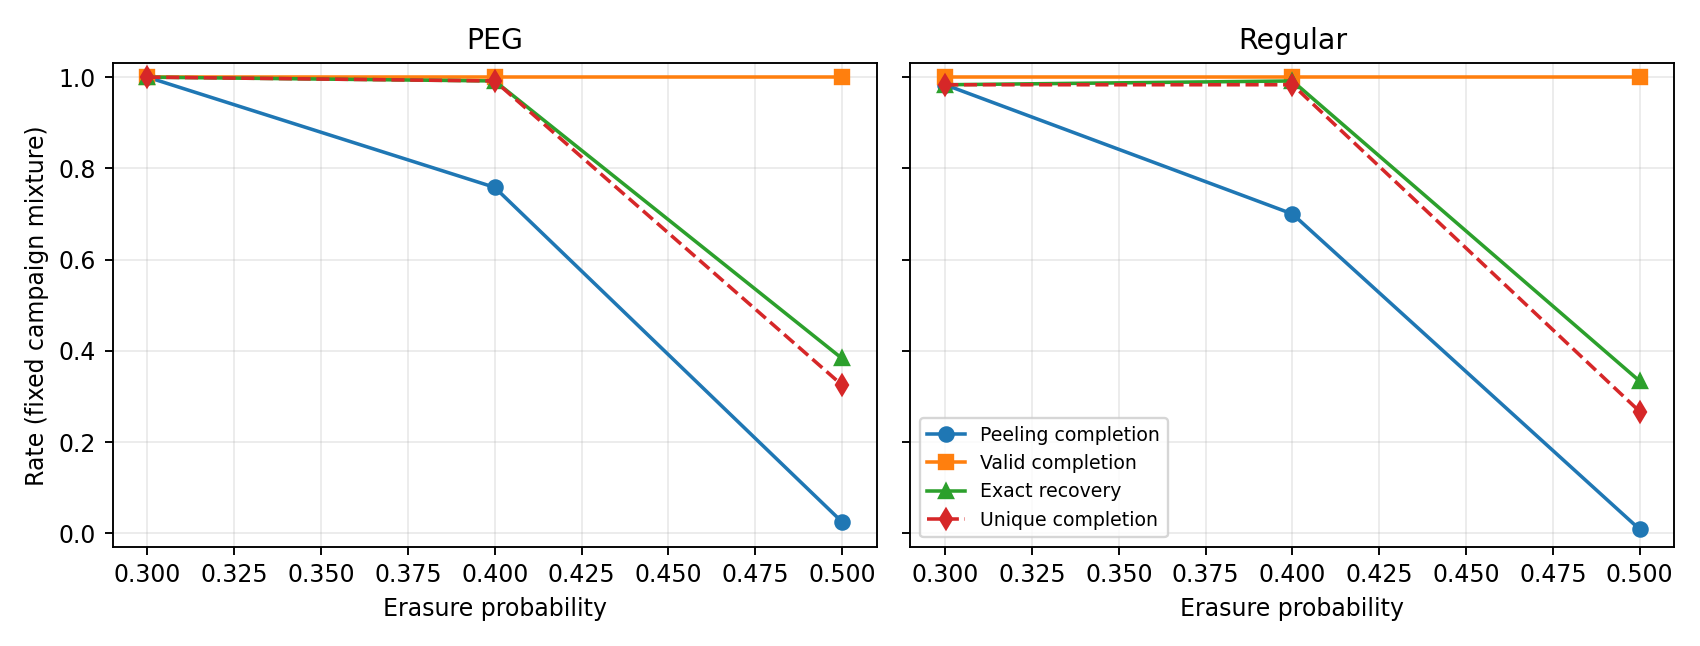

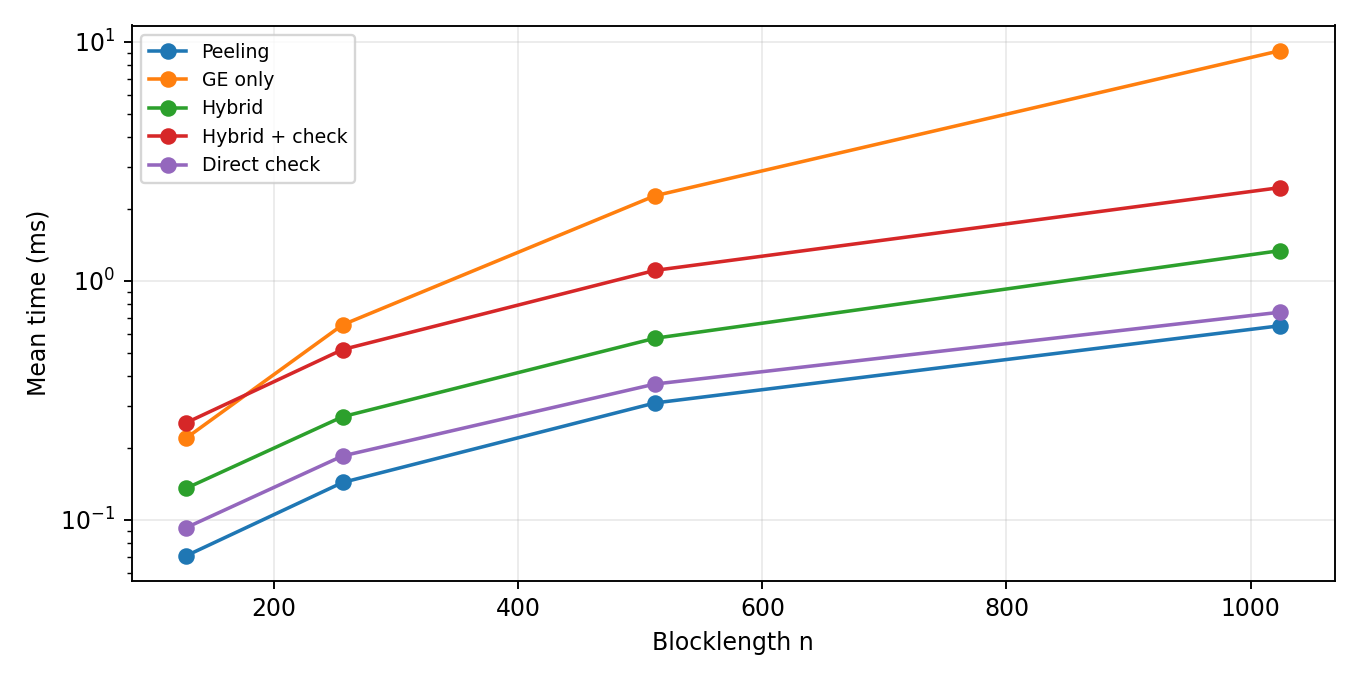

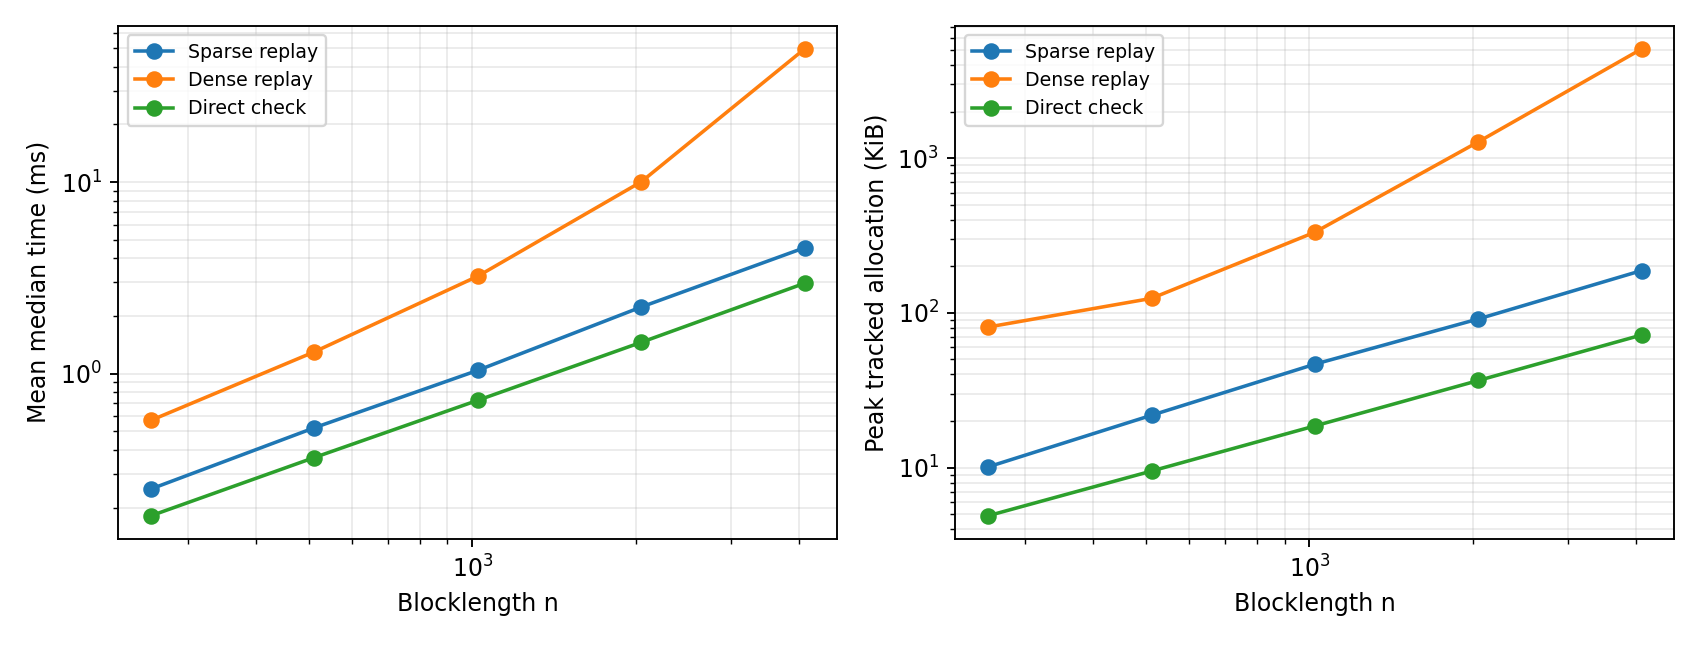

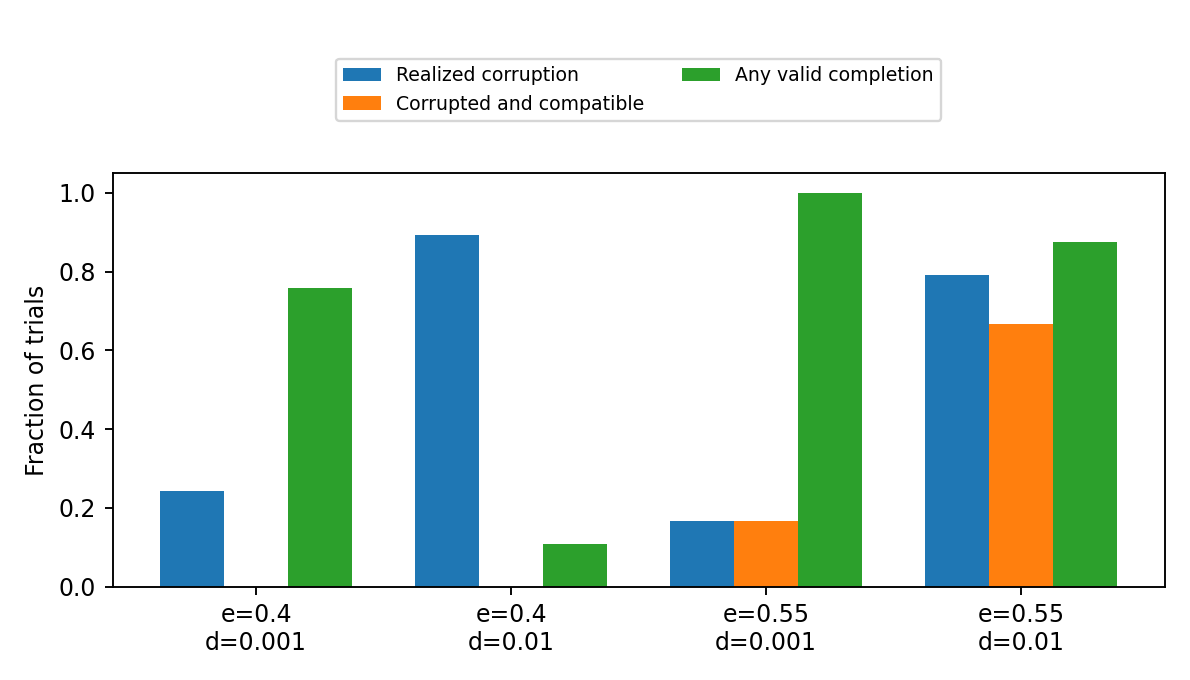

In [4]:
for filename in ["fig_completion.png", "fig_comparators.png", "fig_checker_scaling.png", "fig_corruption.png"]:
    display(Image(filename=str(OUTPUT_DIR / filename)))

## Deterministic adversarial and differential cases

Malformed indices, nonbinary values, inconsistent witnesses and integrity errors must reject. Reordered independent steps and a valid partial trace with a suitable residual assignment may correctly accept. These cases are finite executable checks, not a formal proof of Python correctness. The JSONL corpus can also be passed to the independent Lean runner.

In [5]:
case_summary = generate("audit")
print(case_summary)
display(pd.read_csv("audit/adversarial_results.csv")[["case", "expected_accept", "actual_accept"]])

{'differential_cases': 575, 'accepted': 369, 'rejected': 206, 'named_adversarial_cases': 24, 'all_named_outcomes_expected': True}


,case,expected_accept,actual_accept
0,valid_complete,True,True
1,changed_trace_value,False,False
2,dependent_steps_reversed,False,False
3,check_index_out_of_bounds,False,False
4,variable_index_wrong,False,False
5,duplicate_step,False,False
6,truncated_trace_without_residual,False,False
7,truncated_trace_with_valid_residual,True,True
8,empty_trace_with_valid_residual,True,True
9,residual_bit_changed,False,False


## Definitions and limitations

`decode_s = total_s - check_s`. Here `check_s` is the internal check stage, including comparison of producer/checker output words on success; `trace_check_s` separately measures the standalone checker. The relative certification overhead is `check_s/decode_s`; the checker fraction is `check_s/total_s`. Both the mean of trial ratios and ratio of mean times appear in `condition_summary.csv`. Stages are taken from an actual median-total certified repetition, and complete timing repetitions are saved separately.

The direct verifier is available only for success outputs. Memory measurements are separate from timed repetitions. Matrix generation, graph validation, dense conversion and kernel construction are recorded in `matrix_metadata.csv` and excluded from per-input decoding times. Each decoding time includes input/state initialization. Three independent matrices per condition support only limited claims about an ensemble. Realized corruption is recorded separately from the nominal flip probability, and compatible corruptions do not yield failure certificates.

The manuscript must use the generated data literally. See `audit/EXPERIMENT_REPORT.md` for the executed results and known limitations.